In [1]:
pip install yfinance


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install -U langchain-community


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [32]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph.message import add_messages
from dotenv import load_dotenv

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool
import yfinance as yf
import requests
import random

In [33]:
%pip install -U ddgs


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [34]:
load_dotenv()

True

In [35]:
llm=ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0
)

In [36]:
# first tool
search_tool=DuckDuckGoSearchRun(region="us-en")

In [37]:
# second tool
@tool
def calculator(first_num: float, second_num: float, operation: str) -> dict:
    """
    Perform a basic arithmetic operation on two numbers.
    Supported operations: add, sub, mul, div
    """
    try:
        if operation == "add":
            result = first_num + second_num
        elif operation == "sub":
            result = first_num - second_num
        elif operation == "mul":
            result = first_num * second_num
        elif operation == "div":
            if second_num == 0:
                return {"error": "Division by zero is not allowed"}
            result = first_num / second_num
        else:
            return {"error": f"Unsupported operation '{operation}'"}

        return {"result ": result}

    except Exception as e:
        return {"error": str(e)}

In [38]:
#third tool for stock price

@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch the latest available stock price for a symbol,
    such as AAPL, TSLA, or RELIANCE.NS.
    No API key required.
    """
    try:
        ticker = yf.Ticker(symbol)
        history = ticker.history(period="5d", interval="1d")

        if history.empty:
            return {"error": f"No stock data found for {symbol}"}

        latest = history.iloc[-1]

        return {
            "symbol": symbol.upper(),
            "date": str(history.index[-1].date()),
            "price": round(float(latest["Close"]), 2),
            "currency": "market currency"
        }

    except Exception as e:
        return {"error": str(e)}


In [39]:
tools=[get_stock_price,calculator,search_tool]

llm_with_tool=llm.bind_tools(tools)

In [40]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [41]:
def chat_node(state:ChatState):
    """ LLM node that may answer or request a tool call.""" 
    messages=state['messages']
    response=llm_with_tool.invoke(messages)
    return{"messages":[response]}

tool_node=ToolNode(tools)

In [42]:
graph=StateGraph(ChatState)
graph.add_node('chat_node',chat_node)
graph.add_node('tools', tool_node)

In [43]:
graph.add_edge(START, "chat_node")

graph.add_conditional_edges(
    "chat_node",
    tools_condition
)

graph.add_edge("tools", "chat_node")

In [44]:
chatbot=graph.compile()

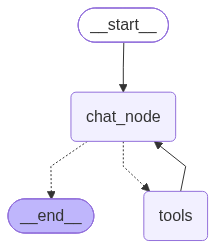

In [45]:
chatbot

In [47]:
out=chatbot.invoke({'messages':[HumanMessage(content='Hello')]})
print(out['messages'][-1].content)

GoogleRateLimitError: Error calling model 'gemini-2.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 7h53m30.200890991s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': '

In [ ]:
response = llm.invoke("What is 2 * 3?")
print(response.content)

GoogleRateLimitError: Error calling model 'gemini-2.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 7h59m26.569287152s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': '

In [17]:
out=chatbot.invoke({'messages':[HumanMessage(content='What is 2*3')]})
print(out['messages'][-1].content)

GoogleRateLimitError: Error calling model 'gemini-2.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 8h47.147157746s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Gen